## The Data

We will be using data from a Kaggle data set:

https://www.kaggle.com/harlfoxem/housesalesprediction

#### Feature Columns
    
* id - Unique ID for each home sold
* date - Date of the home sale
* price - Price of each home sold
* bedrooms - Number of bedrooms
* bathrooms - Number of bathrooms, where .5 accounts for a room with a toilet but no shower
* sqft_living - Square footage of the apartments interior living space
* sqft_lot - Square footage of the land space
* floors - Number of floors
* waterfront - A dummy variable for whether the apartment was overlooking the waterfront or not
* view - An index from 0 to 4 of how good the view of the property was
* condition - An index from 1 to 5 on the condition of the apartment,
* grade - An index from 1 to 13, where 1-3 falls short of building construction and design, 7 has an average level of construction and design, and 11-13 have a high quality level of construction and design.
* sqft_above - The square footage of the interior housing space that is above ground level
* sqft_basement - The square footage of the interior housing space that is below ground level
* yr_built - The year the house was initially built
* yr_renovated - The year of the house’s last renovation
* zipcode - What zipcode area the house is in
* lat - Lattitude
* long - Longitude
* sqft_living15 - The square footage of interior housing living space for the nearest 15 neighbors
* sqft_lot15 - The square footage of the land lots of the nearest 15 neighbors

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../DATA/kc_house_data.csv')

# Exploratory Data Analysis

In [3]:
# kita cek ada missing data atau ga
df.isnull().sum()


id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [4]:
# describe buat liat statistical analysis
df.describe().transpose()

# liatnya susah
# jadi lebih enak di visualize

,count,mean,std,min,25%,50%,75%,max
id,21597.0,4.580474e+09,2.876736e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21597.0,5.402966e+05,3.673681e+05,7.800000e+04,3.220000e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21597.0,3.373200e+00,9.262989e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21597.0,2.115826e+00,7.689843e-01,5.000000e-01,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21597.0,2.080322e+03,9.181061e+02,3.700000e+02,1.430000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21597.0,1.509941e+04,4.141264e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068500e+04,1.651359e+06
floors,21597.0,1.494096e+00,5.396828e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21597.0,7.547345e-03,8.654900e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21597.0,2.342918e-01,7.663898e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21597.0,3.409825e+00,6.505456e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


/Users/clcx/miniforge3/envs/tf-arm64/lib/python3.9/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='price', ylabel='Density'>

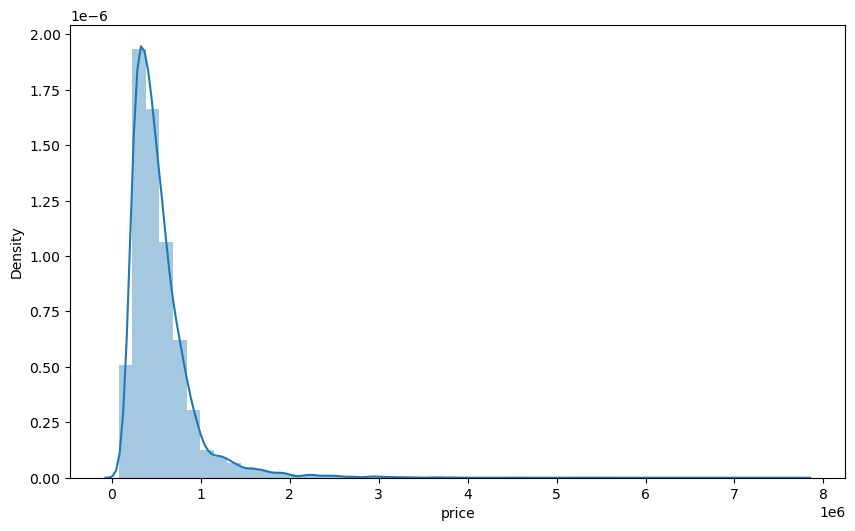

In [5]:
# continuous label pake distribution plot
plt.figure(figsize=(10,6),dpi=100)
sns.distplot(df['price'])

jadi disini kita bisa liat range harga rumahnya 0-2 million, kita plot biar bisa cek ada ga outliers yang misal kalo ada tbtb ada rumah yg mahal sendiri harganya 7 million, jadi kalo training data kita ada outliers kurang akurat nanti hasilnya soalnya kita predictnya cuma di range 0-2 mill

/Users/clcx/miniforge3/envs/tf-arm64/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='bedrooms', ylabel='count'>

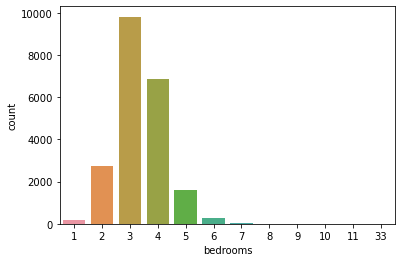

In [6]:
# categorical label pake countplot
sns.countplot(df['bedrooms'])

di atas ada outliers 8-33 itu pasti ada 1 atau bbrp tapi saking dikitnya jadi ga keliatan

In [7]:
# skrg kita coba liat correlation dalem data nya
df.corr()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
id,1.000000,-0.016772,0.001150,0.005162,-0.012241,-0.131911,0.018608,-0.002727,0.011536,-0.023803,0.008188,-0.010799,-0.005193,0.021617,-0.016925,-0.008211,-0.001798,0.020672,-0.002701,-0.138557
price,-0.016772,1.000000,0.308787,0.525906,0.701917,0.089876,0.256804,0.266398,0.397370,0.036056,0.667951,0.605368,0.323799,0.053953,0.126424,-0.053402,0.306692,0.022036,0.585241,0.082845
bedrooms,0.001150,0.308787,1.000000,0.514508,0.578212,0.032471,0.177944,-0.006834,0.080008,0.026496,0.356563,0.479386,0.302808,0.155670,0.018389,-0.154092,-0.009951,0.132054,0.393406,0.030690
bathrooms,0.005162,0.525906,0.514508,1.000000,0.755758,0.088373,0.502582,0.063744,0.188386,-0.126479,0.665838,0.686668,0.283440,0.507173,0.050544,-0.204786,0.024280,0.224903,0.569884,0.088303
sqft_living,-0.012241,0.701917,0.578212,0.755758,1.000000,0.173453,0.353953,0.103854,0.284709,-0.059445,0.762779,0.876448,0.435130,0.318152,0.055308,-0.199802,0.052155,0.241214,0.756402,0.184342
sqft_lot,-0.131911,0.089876,0.032471,0.088373,0.173453,1.000000,-0.004814,0.021632,0.074900,-0.008830,0.114731,0.184139,0.015418,0.052946,0.007686,-0.129586,-0.085514,0.230227,0.144763,0.718204
floors,0.018608,0.256804,0.177944,0.502582,0.353953,-0.004814,1.000000,0.023755,0.028814,-0.264075,0.458794,0.523989,-0.245715,0.489193,0.006427,-0.059541,0.049239,0.125943,0.280102,-0.010722
waterfront,-0.002727,0.266398,-0.006834,0.063744,0.103854,0.021632,0.023755,1.000000,0.401971,0.016611,0.082888,0.072109,0.080559,-0.026153,0.092873,0.030272,-0.014306,-0.041904,0.086507,0.030781
view,0.011536,0.397370,0.080008,0.188386,0.284709,0.074900,0.028814,0.401971,1.000000,0.045999,0.251728,0.167609,0.277078,-0.053636,0.103951,0.084622,0.005871,-0.078107,0.280681,0.072904
condition,-0.023803,0.036056,0.026496,-0.126479,-0.059445,-0.008830,-0.264075,0.016611,0.045999,1.000000,-0.146896,-0.158904,0.173849,-0.361592,-0.060788,0.002888,-0.015102,-0.105877,-0.093072,-0.003126


In [8]:
# coba lebih specific
# kita liat yg correlating sama pricenya
df.corr()['price'].sort_values(ascending=False)

price            1.000000
sqft_living      0.701917
grade            0.667951
sqft_above       0.605368
sqft_living15    0.585241
bathrooms        0.525906
view             0.397370
sqft_basement    0.323799
bedrooms         0.308787
lat              0.306692
waterfront       0.266398
floors           0.256804
yr_renovated     0.126424
sqft_lot         0.089876
sqft_lot15       0.082845
yr_built         0.053953
condition        0.036056
long             0.022036
id              -0.016772
zipcode         -0.053402
Name: price, dtype: float64

udah pasti price korelasi nya 100%, tp kita bisa liat kayak sqft_living, bedrooms, bathroom dll juga korelasi sama harga rumahnya

<AxesSubplot:xlabel='price', ylabel='sqft_living'>

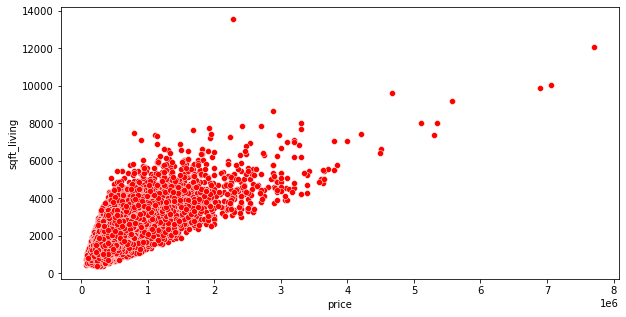

In [9]:
# kita coba plot korelasi sqft_living sama price
plt.figure(figsize=(10,5))
sns.scatterplot(x='price',y='sqft_living',data=df,color='red')

<AxesSubplot:xlabel='bedrooms', ylabel='price'>

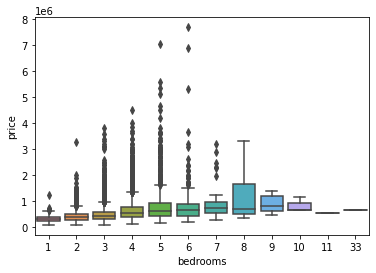

In [10]:
# skrg correlation bedrooms sama price
sns.boxplot(x='bedrooms',y='price',data=df)

### Geographical Properties

skrg kita liat harga rumah berdasarkan latitude(garis lintang) dan longitude (garis bujur)nya

In [11]:
df[['long','lat']]

,long,lat
0,-122.257,47.5112
1,-122.319,47.7210
2,-122.233,47.7379
3,-122.393,47.5208
4,-122.045,47.6168
...,...,...
21592,-122.346,47.6993
21593,-122.362,47.5107
21594,-122.299,47.5944
21595,-122.069,47.5345


<AxesSubplot:xlabel='price', ylabel='long'>

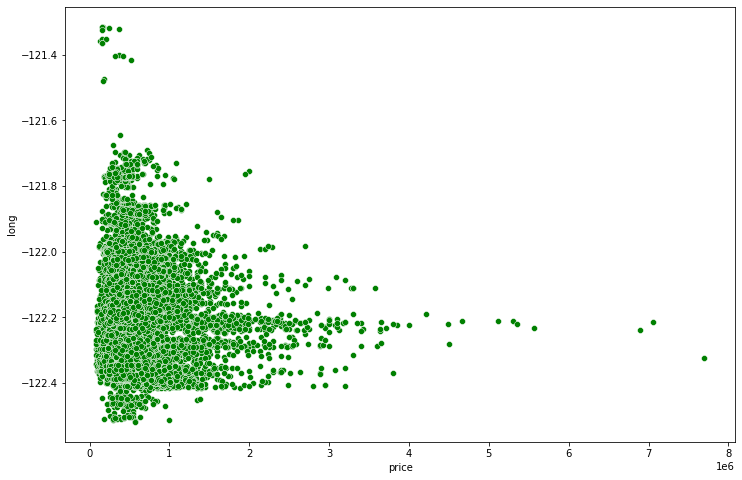

In [12]:
# ga berkorelasi
# TAPI di longitude sekitar -122.2 situ daerah orang kaya
# harga rumah mahal disitu
plt.figure(figsize=(12,8))
sns.scatterplot(x='price',y='long',data=df,color='green')

<AxesSubplot:xlabel='price', ylabel='lat'>

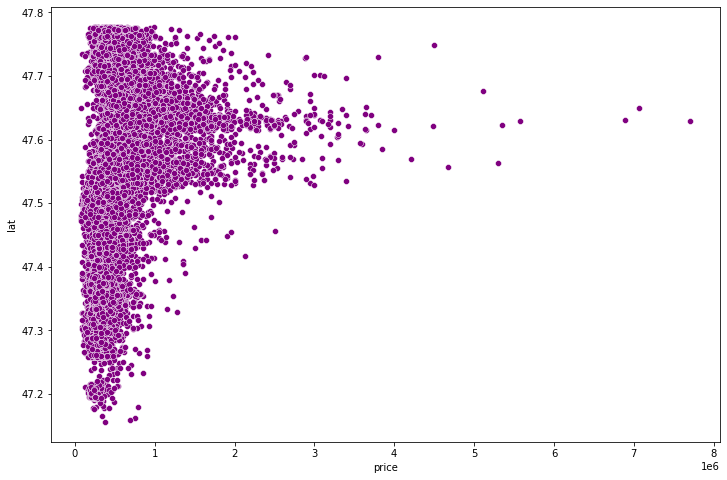

In [13]:
# sama ga berkorelasi
# tapi di lat tertentu itu daerah rumah orang kaya
plt.figure(figsize=(12,8))
sns.scatterplot(x='price',y='lat',data=df,color='purple')

ini gambar peta seatle
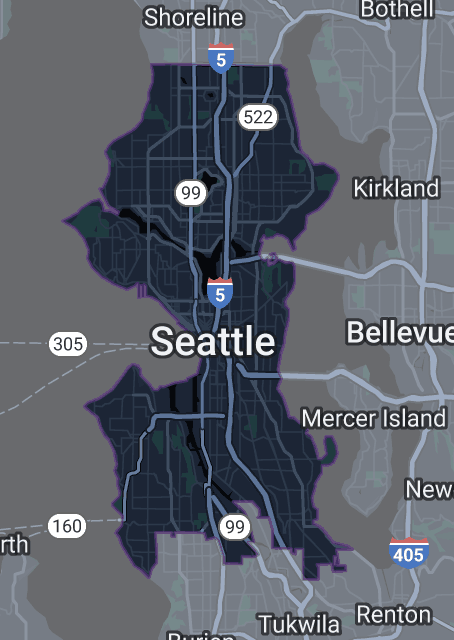
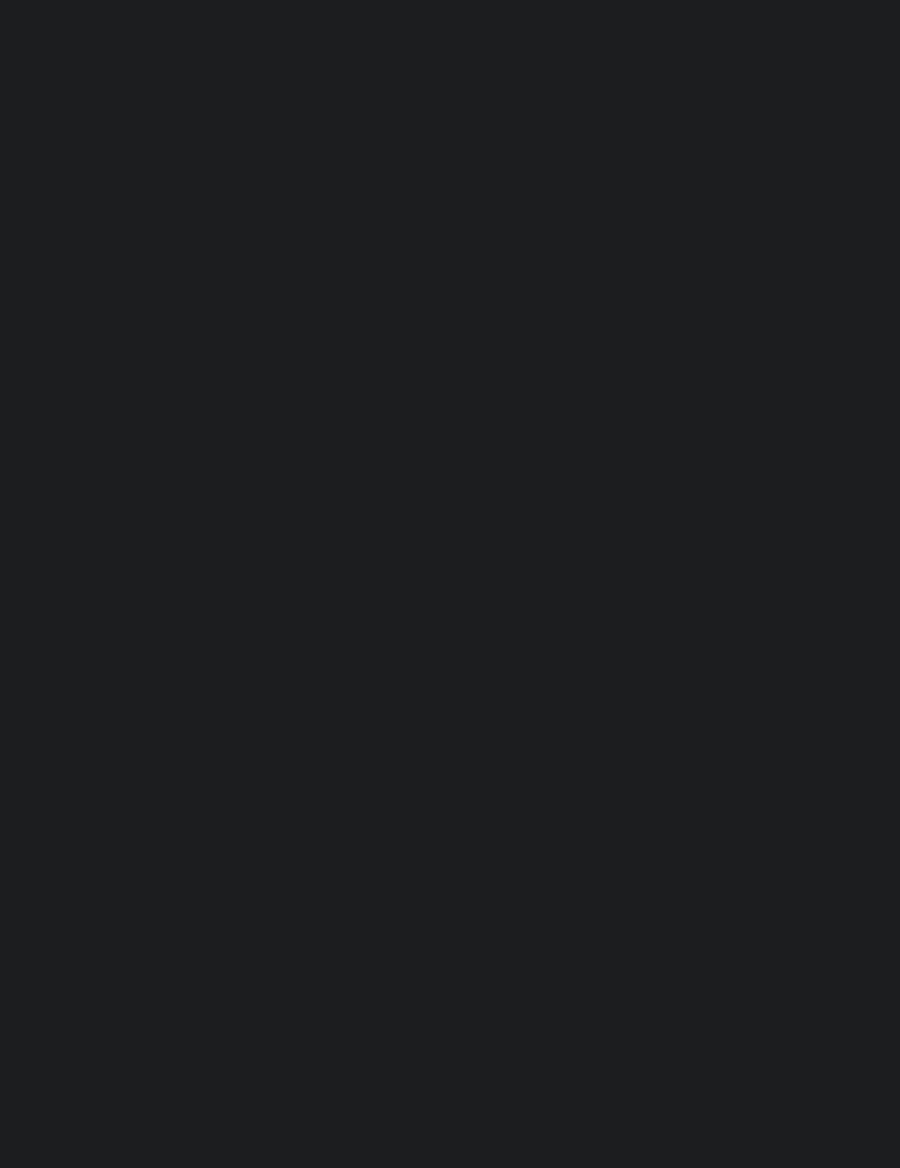

<AxesSubplot:xlabel='long', ylabel='lat'>

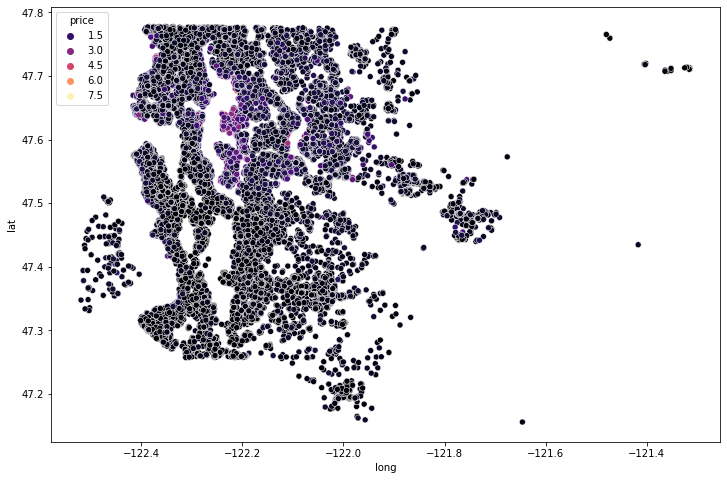

In [14]:
# kita skrg coba plot semua rumah di dataset kita berdasarkan long lat nya
# pasti ngebentuk kota seattle kurang lebih
plt.figure(figsize=(12,8))
sns.scatterplot(x='long',y='lat',data=df,hue='price',palette='magma')

kurang jelas soalnya ada outliers, jadi rangenya kejauan yang di atas, jadi kita coba hilangin yg harga2 nya terlalu tinggu dlu

In [15]:
# kita coba liat 20 harga tertinggi
df.sort_values('price',ascending=False).head(20)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
7245,6762700020,10/13/2014,7700000.0,6,8.00,12050,27600,2.5,0,3,...,13,8570,3480,1910,1987,98102,47.6298,-122.323,3940,8800
3910,9808700762,6/11/2014,7060000.0,5,4.50,10040,37325,2.0,1,2,...,11,7680,2360,1940,2001,98004,47.6500,-122.214,3930,25449
9245,9208900037,9/19/2014,6890000.0,6,7.75,9890,31374,2.0,0,4,...,13,8860,1030,2001,0,98039,47.6305,-122.240,4540,42730
4407,2470100110,8/4/2014,5570000.0,5,5.75,9200,35069,2.0,0,0,...,13,6200,3000,2001,0,98039,47.6289,-122.233,3560,24345
1446,8907500070,4/13/2015,5350000.0,5,5.00,8000,23985,2.0,0,4,...,12,6720,1280,2009,0,98004,47.6232,-122.220,4600,21750
1313,7558700030,4/13/2015,5300000.0,6,6.00,7390,24829,2.0,1,4,...,12,5000,2390,1991,0,98040,47.5631,-122.210,4320,24619
1162,1247600105,10/20/2014,5110000.0,5,5.25,8010,45517,2.0,1,4,...,12,5990,2020,1999,0,98033,47.6767,-122.211,3430,26788
8085,1924059029,6/17/2014,4670000.0,5,6.75,9640,13068,1.0,1,4,...,12,4820,4820,1983,2009,98040,47.5570,-122.210,3270,10454
2624,7738500731,8/15/2014,4500000.0,5,5.50,6640,40014,2.0,1,4,...,12,6350,290,2004,0,98155,47.7493,-122.280,3030,23408
8629,3835500195,6/18/2014,4490000.0,4,3.00,6430,27517,2.0,0,0,...,12,6430,0,2001,0,98004,47.6208,-122.219,3720,14592


In [16]:
# total jumlah data
len(df)

21597

In [17]:
# kita coba hitung 1% nya
len(df)*(0.01)

215.97

In [18]:
# kita coba pisahin bikin df baru buat setelah kita drop 1% harga tertingginya
bottom_99_perc = df.sort_values('price',ascending=False).iloc[216:]

In [19]:
bottom_99_perc.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
6329,824059321,6/2/2014,1970000.0,4,3.50,4370,8510,2.0,0,1,...,10,3610,760,2003,0,98004,47.5876,-122.204,2960,10347
12271,1923000260,10/15/2014,1960000.0,5,4.50,6200,23373,3.0,0,1,...,11,5050,1150,1988,0,98040,47.5632,-122.215,3700,14486
9166,3124059023,2/13/2015,1960000.0,3,1.75,3330,12566,1.0,1,4,...,8,1940,1390,1960,0,98040,47.5287,-122.220,3730,16560
12565,2806300065,4/22/2015,1960000.0,4,4.00,4430,31353,2.0,0,0,...,12,4430,0,1998,0,98005,47.6422,-122.157,3900,35237
1150,4055701200,4/21/2015,1960000.0,4,2.75,3120,7898,1.0,1,4,...,8,1560,1560,1963,0,98034,47.7165,-122.259,2630,13868


<AxesSubplot:xlabel='long', ylabel='lat'>

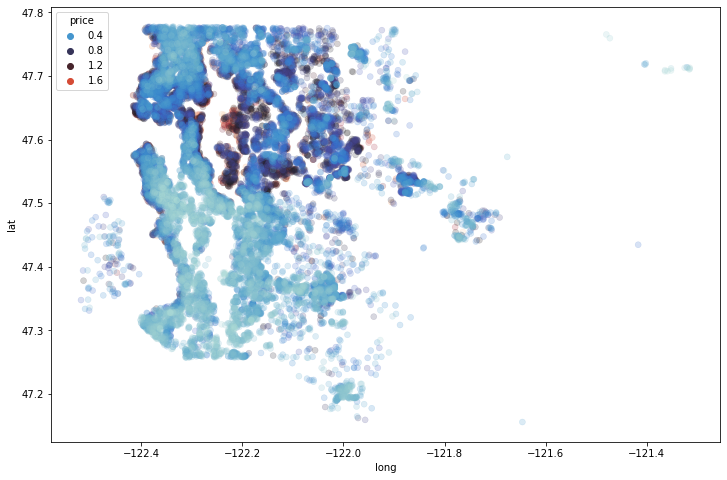

In [20]:
# skrg lebih jelas mana daerah yang mahal
# yg mahal itu lebih ke daerah2 yg deket air, atau yg punya waterfront
# di pinggir2 land nya lebih mahal
plt.figure(figsize=(12,8))
sns.scatterplot(x='long',y='lat',hue='price',data=bottom_99_perc,
                edgecolor=None,alpha=0.2,palette='icefire')

<AxesSubplot:xlabel='waterfront', ylabel='price'>

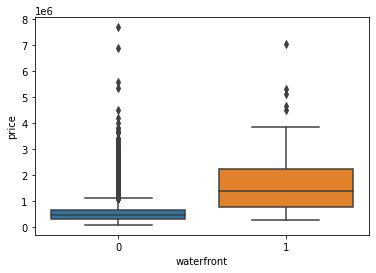

In [21]:
# coba kita plot waterfront
sns.boxplot(x='waterfront',y='price',data=df)

## Working with Feature Data
skrg kita mulai feature engineering

In [22]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,10/13/2014,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,12/9/2014,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,2/25/2015,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,12/9/2014,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,2/18/2015,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21597 non-null  int64  
 1   date           21597 non-null  object 
 2   price          21597 non-null  float64
 3   bedrooms       21597 non-null  int64  
 4   bathrooms      21597 non-null  float64
 5   sqft_living    21597 non-null  int64  
 6   sqft_lot       21597 non-null  int64  
 7   floors         21597 non-null  float64
 8   waterfront     21597 non-null  int64  
 9   view           21597 non-null  int64  
 10  condition      21597 non-null  int64  
 11  grade          21597 non-null  int64  
 12  sqft_above     21597 non-null  int64  
 13  sqft_basement  21597 non-null  int64  
 14  yr_built       21597 non-null  int64  
 15  yr_renovated   21597 non-null  int64  
 16  zipcode        21597 non-null  int64  
 17  lat            21597 non-null  float64
 18  long  

In [24]:
# id nya kita ga butuh, boleh kita drop aja
df = df.drop('id',axis=1)

In [25]:
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,10/13/2014,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,12/9/2014,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2/25/2015,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,12/9/2014,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,2/18/2015,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


### Feature Engineering from Date

In [26]:
# kita liat datenya
df['date']

# dtypenya object, artinya cuma string

0        10/13/2014
1         12/9/2014
2         2/25/2015
3         12/9/2014
4         2/18/2015
            ...    
21592     5/21/2014
21593     2/23/2015
21594     6/23/2014
21595     1/16/2015
21596    10/15/2014
Name: date, Length: 21597, dtype: object

In [27]:
# kita ubah jadi datetime
df['date'] = pd.to_datetime(df['date'])

In [28]:
df['date']

0       2014-10-13
1       2014-12-09
2       2015-02-25
3       2014-12-09
4       2015-02-18
           ...    
21592   2014-05-21
21593   2015-02-23
21594   2014-06-23
21595   2015-01-16
21596   2014-10-15
Name: date, Length: 21597, dtype: datetime64[ns]

In [29]:
# skrg kita bisa pisahin month sama yearnya ke column baru
# biar nanti kita bisa liat corr nya sama price

# year
df['year'] = df['date'].apply(lambda date:date.year)

In [30]:
# month
df['month'] = df['date'].apply(lambda date:date.month)

In [31]:
# RECALL LAMBDA
# sama aja kayak isi function ini
def year_extraction(date):
    return date.year

<AxesSubplot:xlabel='year', ylabel='price'>

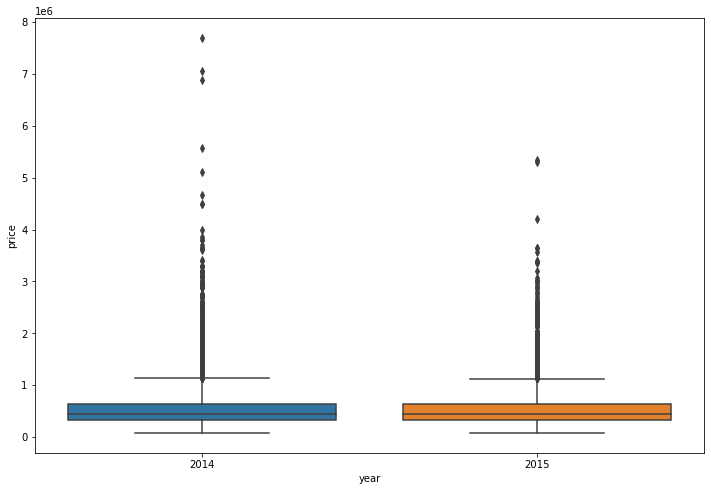

In [32]:
# dari year kurang keliatan
plt.figure(figsize=(12,8))
sns.boxplot(x='year',y='price',data=df)

<AxesSubplot:xlabel='month', ylabel='price'>

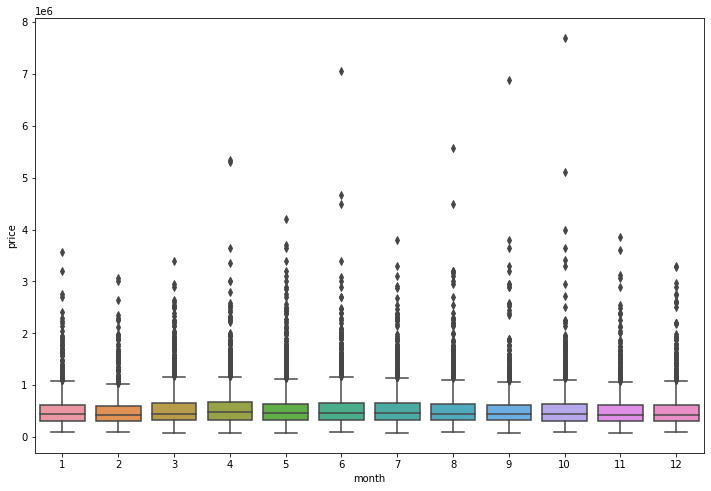

In [33]:
# coba liat dari month
# apa mungkin bulan2 tertentu mahal
plt.figure(figsize=(12,8))
sns.boxplot(x='month',y='price',data=df)

kalo gini masih ga keliatan jadi kita pake groupby

In [34]:
df.groupby('month').mean()['price']

month
1     525963.251534
2     508520.051323
3     544057.683200
4     562215.615074
5     550849.746893
6     557534.318182
7     544892.161013
8     536655.212481
9     529723.517787
10    539439.447228
11    522359.903478
12    524799.902041
Name: price, dtype: float64

<AxesSubplot:xlabel='month'>

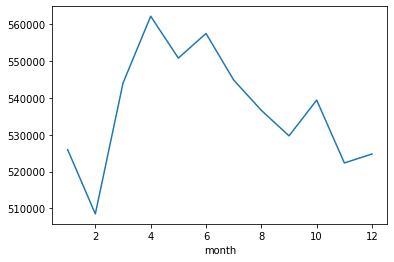

In [35]:
# terus kita plot
df.groupby('month').mean()['price'].plot()

disini keliatan ada behaviour berdasarkan bulannya, tapi range nya ga gitu jauh cuma 510k - 560k

<AxesSubplot:xlabel='year'>

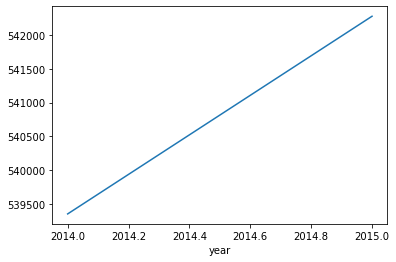

In [36]:
# kita plot juga buat tahunnya
df.groupby('year').mean()['price'].plot()

# harga tahunan wajar makin mahal karena inflasi dll

In [37]:
# kita bisa drop column datenya soalnya udah kita feature engineer, 
# udah di extract bulan sama tahunnya
df = df.drop('date',axis=1)

In [38]:
df.columns

Index(['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'sqft_living15', 'sqft_lot15', 'year', 'month'],
      dtype='object')

In [39]:
df.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,year,month
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,...,0,1955,0,98178,47.5112,-122.257,1340,5650,2014,10
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,...,400,1951,1991,98125,47.7210,-122.319,1690,7639,2014,12
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,...,0,1933,0,98028,47.7379,-122.233,2720,8062,2015,2
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,...,910,1965,0,98136,47.5208,-122.393,1360,5000,2014,12
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,...,0,1987,0,98074,47.6168,-122.045,1800,7503,2015,2


In [40]:
# skrg kita cek2 feature nya

In [41]:
# zipcode
# kita coba liat dulu value_counts nya
df['zipcode'].value_counts()

98103    602
98038    589
98115    583
98052    574
98117    553
        ... 
98102    104
98010    100
98024     80
98148     57
98039     50
Name: zipcode, Length: 70, dtype: int64

ada 70 zipcode beda, kita musti tentuin kita mau dia sebagai categorical atau continous, jadi kita liat dulu correlation nya sama di peta

### Zipcode
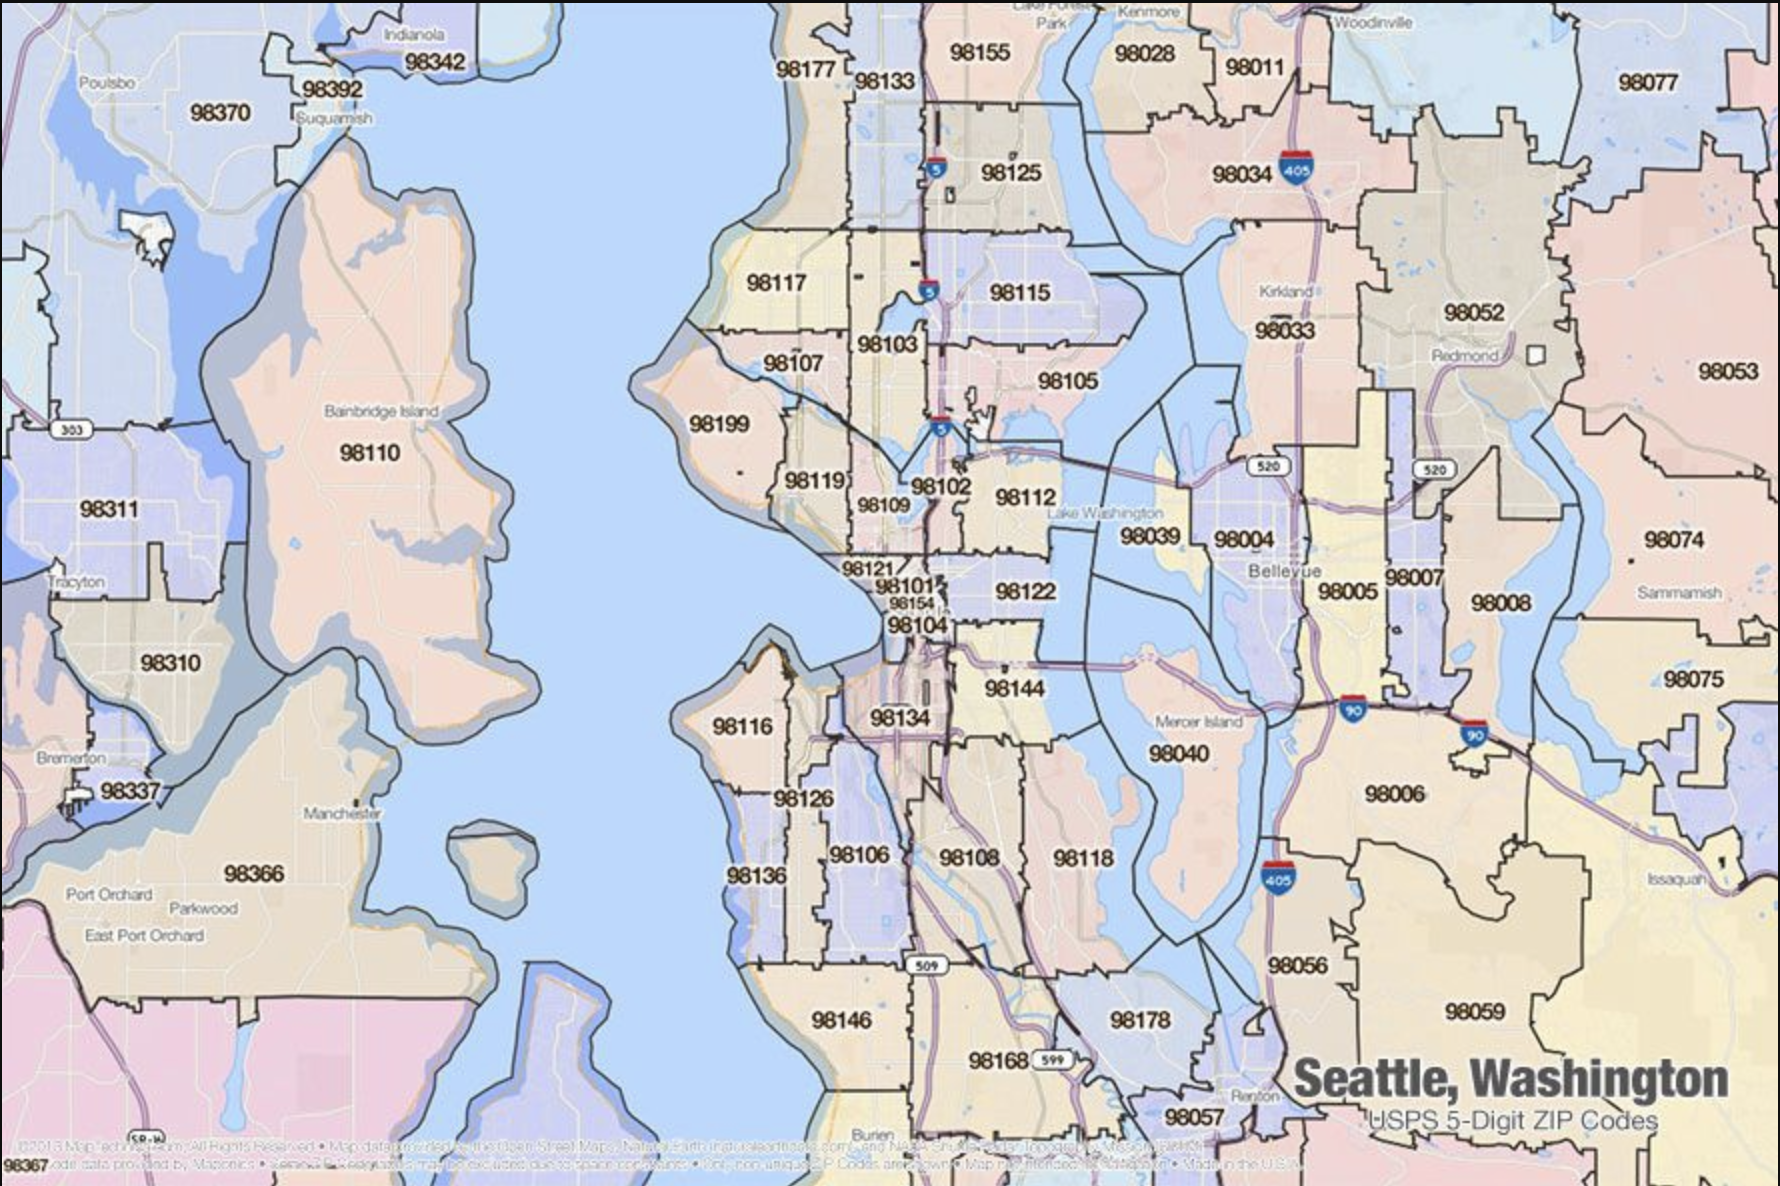


dan ternyata ga ada hubungan continousnya, artinya ga ada misal zipcode lebih gede itu lebih bagus daerahnya, jadi totally random, berarti categorical. TAPI 70 categorical values itu kebanyakan, jadi kalo mau kita bisa bikin categorical berdasarkan daerah bagian, atau misal selatan utara barat timur, cuma butuh kerjaan manual yang lumayan. Jadi itu pentingnya ML engineer contact sama orang yg expert, contohnya real estate agent yg ngerti daerah2 nya. jadi untuk case ini kita drop aja zipcodenya

In [42]:
df = df.drop('zipcode',axis=1)

In [43]:
df.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,year,month
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,2014,10
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,2014,12
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,2015,2
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,2014,12
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,2015,2


In [44]:
# yr_renovated
df['yr_renovated'].value_counts()

0       20683
2014       91
2013       37
2003       36
2005       35
        ...  
1951        1
1959        1
1948        1
1954        1
1944        1
Name: yr_renovated, Length: 70, dtype: int64

skrg ini kita tentuin lagi mau categorical atau continous, harusnya kita bisa bikin categorical pake dummy variables (0/1), jadi yang '0' itu kan artinya ga direnovasi, yang ada tahunnya berarti udah di renov kita kasih value '1'

cuma kita bisa pake tahunnya sebagai advantage buat kita, soalnya tahun renov nya makin baru berarti valuenya makin besar harusnya, jadi kita mending keep ini sebagai continous value

In [45]:
# sqft_basement
# ini kita treat continous juga, alesannya sama kayak renov
df['sqft_basement'].value_counts()

0      13110
600      221
700      218
500      214
800      206
       ...  
518        1
374        1
784        1
906        1
248        1
Name: sqft_basement, Length: 306, dtype: int64

## Scaling and Train Test Split

In [46]:
X = df.drop('price',axis=1).values
y = df['price'].values

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

### Scaling

In [49]:
from sklearn.preprocessing import MinMaxScaler

In [50]:
scaler = MinMaxScaler()

In [51]:
X_train = scaler.fit_transform(X_train)

In [52]:
X_test = scaler.transform(X_test)

In [53]:
X_train.shape

(15117, 19)

In [54]:
X_test.shape

(6480, 19)

In [55]:
df.shape

(21597, 20)

## Creating a Model

In [56]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.optimizers import Adam

In [57]:
X_train.shape

(15117, 19)

In [58]:
model = Sequential()

# ada 19 features, jadi kita pake 19 units
# layers nya 4 dlu, harusnya bakalan overkill jadi bakal overfit
# cuma nanti di test pake validation data
model.add(Dense(19,activation='relu'))
model.add(Dense(19,activation='relu'))
model.add(Dense(19,activation='relu'))
model.add(Dense(19,activation='relu'))
model.add(Dense(1))

model.compile(optimizer='adam',loss='mse')

Metal device set to: Apple M1

systemMemory: 8.00 GB
maxCacheSize: 2.67 GB



2022-09-15 16:30:05.355158: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2022-09-15 16:30:05.355500: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [59]:
model.fit(x=X_train,y=y_train,validation_data=(X_test,y_test),batch_size=128,epochs=400)

Epoch 1/400


2022-09-15 16:30:05.486894: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


  1/119 [..............................] - ETA: 50s - loss: 434068324352.0000

2022-09-15 16:30:05.800023: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:113] Plugin optimizer for device_type GPU is enabled.


119/119 [==============================] - 1s 7ms/step - loss: 430232207360.0000 - val_loss: 418867838976.0000
Epoch 2/400
  1/119 [..............................] - ETA: 0s - loss: 396670992384.0000

2022-09-15 16:30:06.609477: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:113] Plugin optimizer for device_type GPU is enabled.


119/119 [==============================] - 1s 6ms/step - loss: 428656001024.0000 - val_loss: 413571186688.0000
Epoch 3/400
119/119 [==============================] - 1s 6ms/step - loss: 409171394560.0000 - val_loss: 370286460928.0000
Epoch 4/400
119/119 [==============================] - 1s 6ms/step - loss: 319470010368.0000 - val_loss: 230381846528.0000
Epoch 5/400
119/119 [==============================] - 1s 6ms/step - loss: 163525951488.0000 - val_loss: 105783410688.0000
Epoch 6/400
119/119 [==============================] - 1s 6ms/step - loss: 100734328832.0000 - val_loss: 94877032448.0000
Epoch 7/400
119/119 [==============================] - 1s 6ms/step - loss: 97204584448.0000 - val_loss: 93320544256.0000
Epoch 8/400
119/119 [==============================] - 1s 6ms/step - loss: 95489253376.0000 - val_loss: 91648770048.0000
Epoch 9/400
119/119 [==============================] - 1s 6ms/step - loss: 93766647808.0000 - val_loss: 90060587008.0000
Epoch 10/400
119/119 [=============

In [63]:
# karena kita pake validation data, jadi kita bisa liat loss sama val_loss nya
pd.DataFrame(model.history.history)


,loss,val_loss
0,4.302322e+11,4.188678e+11
1,4.286560e+11,4.135712e+11
2,4.091714e+11,3.702865e+11
3,3.194700e+11,2.303818e+11
4,1.635260e+11,1.057834e+11
...,...,...
395,2.953757e+10,2.750971e+10
396,2.953625e+10,2.741264e+10
397,2.949194e+10,2.735188e+10
398,2.950240e+10,2.736244e+10


In [64]:
# kita bisa compare loss training sama loss validation pake plot
losses = pd.DataFrame(model.history.history)

<AxesSubplot:>

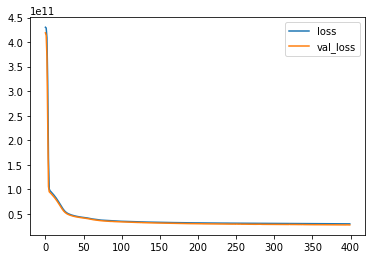

In [65]:
losses.plot()

kita bisa liat makin akhir improvement nya udah makin kecil, berarti 400 epochs ga cukup, masih bisa lanjut training. Cuma kita harus perhatiin juga, kalo misal loss trainingnya tbtb naik jauh bgt, berarti errornya jadi gede bgt itu artinya overfitting, tapi kalo val_loss sama loss nya masih sama, berarti masih bisa lanjut training

# Evaluation on Test Data

https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics

In [66]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,explained_variance_score

#### Predicting on Brand New Data

In [68]:
pd.DataFrame(X_test)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,0.1,0.08,0.042399,0.004695,0.0,0.0,0.0,0.75,0.3,0.054594,0.000000,0.208696,0.0,0.875181,0.181894,0.313371,0.008877,0.0,0.636364
1,0.3,0.36,0.172699,0.005134,0.0,0.0,0.0,0.75,0.5,0.118509,0.161826,0.643478,0.0,0.820492,0.277409,0.356393,0.009937,0.0,0.818182
2,0.2,0.24,0.125129,0.002114,0.0,0.0,0.0,0.75,0.4,0.055925,0.163900,0.078261,0.0,0.838025,0.122924,0.163655,0.005471,0.0,0.909091
3,0.1,0.08,0.057911,0.003550,0.0,0.0,0.0,0.75,0.4,0.074567,0.000000,0.347826,0.0,0.861509,0.164452,0.134400,0.006672,0.0,0.545455
4,0.2,0.16,0.113754,0.005482,0.0,0.0,0.0,0.50,0.4,0.121172,0.039419,0.356522,0.0,0.880328,0.176910,0.170539,0.010392,1.0,0.272727
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6475,0.3,0.44,0.314374,0.020849,0.4,0.0,0.0,0.75,0.6,0.279627,0.195021,0.800000,0.0,0.487534,0.428571,0.352951,0.044766,1.0,0.272727
6476,0.2,0.16,0.086867,0.002835,0.0,0.0,0.0,1.00,0.3,0.111851,0.000000,0.600000,0.0,0.330706,0.358804,0.124075,0.005296,1.0,0.090909
6477,0.1,0.08,0.055843,0.002593,0.0,0.0,0.0,0.75,0.4,0.071904,0.000000,0.200000,0.0,0.639698,0.117940,0.180864,0.005063,0.0,1.000000
6478,0.3,0.20,0.222337,0.004046,0.0,0.0,0.5,1.00,0.4,0.118509,0.261411,0.478261,0.0,0.526942,0.271595,0.337463,0.007745,1.0,0.090909


In [69]:
# kita coba predict 
predictions = model.predict(X_test)

2022-09-16 16:38:00.872270: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:113] Plugin optimizer for device_type GPU is enabled.


In [70]:
# skrg kita liat MAE sama RMSE nya
mean_absolute_error(y_test,predictions)


101880.35043282215

In [71]:
np.sqrt(mean_squared_error(y_test,predictions))

165286.7611009637

bagus atau ga? errornya gede atau ga? kita cek df kita

In [74]:
df['price'].describe()

count    2.159700e+04
mean     5.402966e+05
std      3.673681e+05
min      7.800000e+04
25%      3.220000e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

In [75]:
# mean
5.402966e+05

540296.6

100k itu lumayan jauh dari 540k, off sekitar 20%, ga jelek, ga bagus juga

In [76]:
# skrg kita cek variance scorenya
# max score nya 1.0
explained_variance_score(y_test,predictions)

0.7940434431108307

0.79 sebenernya ga buruk, cuma kita skrg ga ada perbandingan sama model yang lain, jadi gatau bagus atau ga

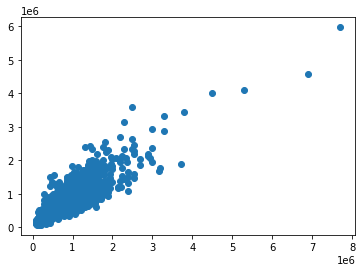

In [77]:
# skrg kita coba plot predictions nya
plt.scatter(y_test,predictions)

# perfect predictions itu harusnya garis lurus linear

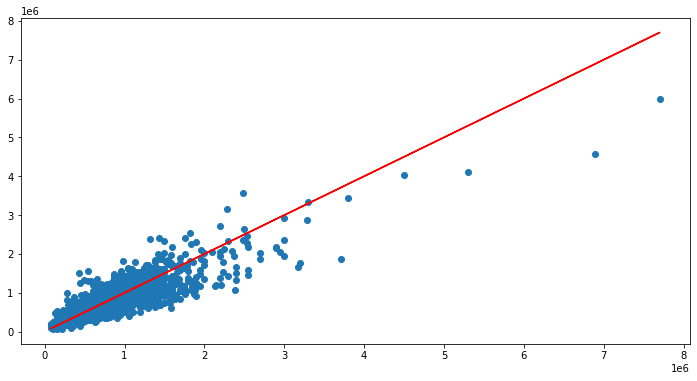

In [81]:
# kita coba plot 2-2nya
plt.figure(figsize=(12,6))

# Our predictions
plt.scatter(y_test,predictions)

# Perfect predictions
plt.plot(y_test,y_test,'r')

bisa kita liat sebenernya untuk harga range 2 million itu prediksinya lumayan bagus, tapi yang mahal2 sama outliers kurang, JADI yang bisa kita lakuin adalah kita engineer lagi datanya, kita drop 1% atas, terus kita lanjut train lg modelnya

In [87]:
y_test.shape

(6480,)

In [88]:
predictions.shape

(6480, 1)

In [89]:
# kita samain shapenya
errors = y_test.reshape(6480,1) - predictions

/Users/clcx/miniforge3/envs/tf-arm64/lib/python3.9/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:ylabel='Density'>

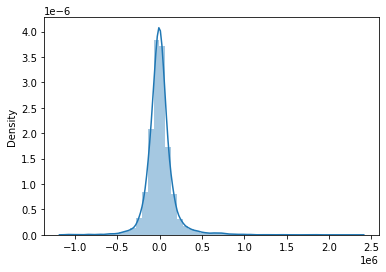

In [90]:
sns.distplot(errors)

### Predicting on a brand new house

In [91]:
# kita coba ambil contoh rumah dari df kita, terus kita drop pricenya
df.head(1)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,year,month
0,221900.0,3,1.0,1180,5650,1.0,0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,2014,10


In [92]:
singe_house = df.drop('price',axis=1).iloc[0]

In [93]:
singe_house

bedrooms            3.0000
bathrooms           1.0000
sqft_living      1180.0000
sqft_lot         5650.0000
floors              1.0000
waterfront          0.0000
view                0.0000
condition           3.0000
grade               7.0000
sqft_above       1180.0000
sqft_basement       0.0000
yr_built         1955.0000
yr_renovated        0.0000
lat                47.5112
long             -122.2570
sqft_living15    1340.0000
sqft_lot15       5650.0000
year             2014.0000
month              10.0000
Name: 0, dtype: float64

In [94]:
# kurung kotak nya cuma 1, harusnya 2, jadi kita reshape dlu
singe_house.values

array([ 3.00000e+00,  1.00000e+00,  1.18000e+03,  5.65000e+03,
        1.00000e+00,  0.00000e+00,  0.00000e+00,  3.00000e+00,
        7.00000e+00,  1.18000e+03,  0.00000e+00,  1.95500e+03,
        0.00000e+00,  4.75112e+01, -1.22257e+02,  1.34000e+03,
        5.65000e+03,  2.01400e+03,  1.00000e+01])

In [97]:
singe_house.values.reshape(-1,19)

array([[ 3.00000e+00,  1.00000e+00,  1.18000e+03,  5.65000e+03,
         1.00000e+00,  0.00000e+00,  0.00000e+00,  3.00000e+00,
         7.00000e+00,  1.18000e+03,  0.00000e+00,  1.95500e+03,
         0.00000e+00,  4.75112e+01, -1.22257e+02,  1.34000e+03,
         5.65000e+03,  2.01400e+03,  1.00000e+01]])

In [98]:
# terus kita scale
singe_house = scaler.transform(singe_house.values.reshape(-1,19))

In [99]:
singe_house

array([[0.2       , 0.08      , 0.08376422, 0.00310751, 0.        ,
        0.        , 0.        , 0.5       , 0.4       , 0.10785619,
        0.        , 0.47826087, 0.        , 0.57149751, 0.21760797,
        0.16193426, 0.00582059, 0.        , 0.81818182]])

In [100]:
# predict
model.predict(singe_house)

array([[283282.88]], dtype=float32)

In [102]:
df['price'][0]

221900.0

hasil prediksi 283k, aslinya 221k, off lumayan, gabagus ga jelek